# nmr.retrieval.h.m2s

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.retrieval.h.m2s')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "nmr.retrieval.h.m2s",
  "status": "recorded_results",
  "source_sha256": {
    "nmr_documented_examples_20261117_v2.json": "669413d6fc0939bdb6826782d41fc13cf12926a672418ecb46303f0b8ba05b99"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1"
  },
  "reference_smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
  "output": {
    "length": 10,
    "first_values": [
      {
        "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
        "score": 0.8390898108482361,
        "reference_match": true
      },
      {
        "smiles": "CC(C)(C)C1=CC(=Cc2ccc(Cl)cc2)C=C(C(C)(C)C)C1=O",
        "score": 0.4334178566932678,
        "reference_match": false
      },
      {
        "smiles": "CC1=C2CCCCCCCCCCC2OC1=O",
        "score": 0.35564976930618286,
        "reference_match": false
      },
      {
        "smiles": "CC(C)(C)OC(=O)N[C@H](CCC(=O)c1ccccc1)c1c[nH]c2cc(Cl)ccc12",
        "score": 0.16095159947872162,
        "reference_match": false
      },
      {
        "smiles": "COC(=O)c1cc(-c2ccccc2)n(N)c1C",
        "score": 0.14309056103229523,
        "reference_match": false
      },
      {
        "smiles": "FC(F)(F)C1(C#Cc2ccsc2)CNCC1c1ccccc1",
        "sc

## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| nmrspec_test | recorded model | recall_at_1 | 1 |
| nmrspec_test | recorded model | mrr | 1 |
| nmrspec_test | recorded model | queries | 32 |
| nmrspec_test | recorded model | candidate_pool | 32 |
| patent_test_10k | recorded model | recall_at_1 | 0.625 |
| patent_test_10k | recorded model | mrr | 0.775298 |
| patent_test_10k | recorded model | queries | 32 |
| patent_test_10k | recorded model | candidate_pool | 32 |
| nmrexp_exp_10k | recorded model | recall_at_1 | 0.84375 |
| nmrexp_exp_10k | recorded model | mrr | 0.88776 |
| nmrexp_exp_10k | recorded model | queries | 32 |
| nmrexp_exp_10k | recorded model | candidate_pool | 32 |
| nmrgym_test | recorded model | recall_at_1 | 0.65625 |
| nmrgym_test | recorded model | mrr | 0.749297 |
| nmrgym_test | recorded model | queries | 32 |
| nmrgym_test | recorded model | candidate_pool | 32 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 4,
  "real_examples": 3
}


## 预测／参考对照图

输入输出对应合理，但目前主要是 32 候选的小池检查。先评更大的独立候选库，再判断泛化和微调需求。

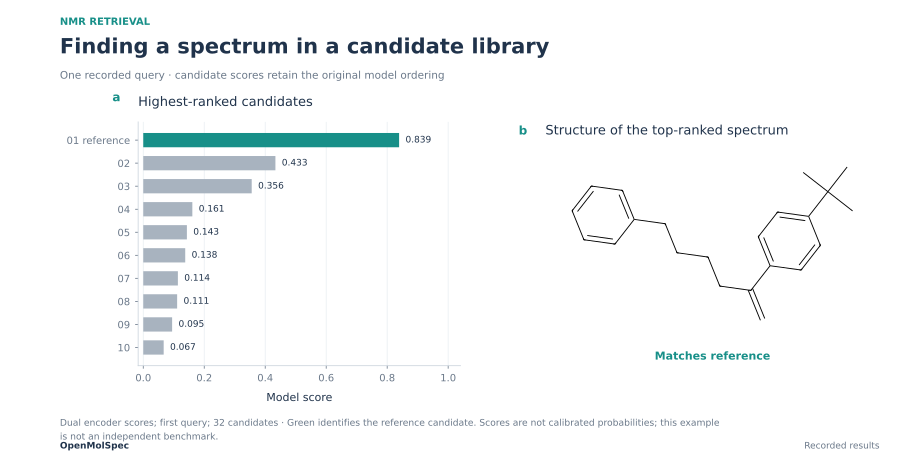

In [4]:
figure = render('nmr.retrieval.h.m2s', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/nmr-retrieval-h-m2s.md) · [Quick Start](../quickstart.md)
